# Polinomio de Lagrange

 Dependencias e imports

In [13]:
%pip install numpy pandas matplotlib scipy openpyxl --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import urllib.request
from openpyxl import load_workbook

In [15]:
archivo = "Hong Kong.xlsx"
url="https://raw.githubusercontent.com/Caro405/Pry_numerico/main/Hong%20Kong.xlsx"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

wb = load_workbook(archivo)
ws = wb.active



## Carga de los datos

In [16]:
if os.path.exists(archivo):
    df = pd.read_excel(archivo, header=0, usecols="B:C")
    df.columns = ["Año", "Población"]
    df = df.dropna().reset_index(drop=True)
    print("Archivo leido correctamente")
else:
    print("Archivo Excel no encontrado")

print(df)

Archivo leido correctamente
     Año  Población
0   1994    6042259
1   1995    6177105
2   1996    6302469
3   1997    6416674
4   1998    6521331
5   1999    6616524
6   2000    6704665
7   2001    6774243
8   2002    6821412
9   2003    6858906
10  2004    6888164
11  2005    6908483
12  2006    6931089
13  2007    6971344
14  2008    7020689
15  2009    7064464
16  2010    7101614
17  2011    7142969
18  2012    7201059
19  2013    7264330
20  2014    7319502
21  2015    7366411
22  2016    7408006
23  2017    7444889
24  2018    7471190
25  2019    7485817
26  2020    7490240
27  2021    7484604
28  2022    7465913
29  2023    7442738


## Detección de los años subrayados

In [17]:
anios_sub_auto = []
datos_anios = []
datos_poblacion = []

for fila in range(2, ws.max_row + 1):
    celda_anio = ws.cell(row=fila, column=2)
    celda_pob = ws.cell(row=fila, column=3)

    if celda_anio.value is not None and celda_pob.value is not None:
        anio = int(celda_anio.value)
        pob = float(celda_pob.value)

        datos_anios.append(anio)
        datos_poblacion.append(pob)

        # Revisar el color de fondo de la celda del año
        color_fondo = celda_anio.fill.start_color

        es_subrayado = False

        if color_fondo.type == 'rgb':
            # Filtrar los colores blancos (FFFFFFFF) y negros (00000000)
            if color_fondo.rgb not in ['FFFFFFFF', '00000000']:
                es_subrayado = True
        elif color_fondo.type == 'theme':
              if color_fondo.theme not in [0, 1]:
                es_subrayado = True

        if es_subrayado:
            anios_sub_auto.append(anio)

print(f"Años detectados automáticamente como subrayados: {anios_sub_auto}")

df = pd.DataFrame({"Año": datos_anios, "Población": datos_poblacion})

Años detectados automáticamente como subrayados: [1995, 2000, 2008, 2015, 2022]


## Separación de datos

In [18]:
mask_sub = df["Año"].isin(anios_sub_auto)
df_train = df[~mask_sub].reset_index(drop=True)   # 25 datos
df_test  = df[ mask_sub].reset_index(drop=True)   # 5 datos

print(f"Datos de prueba (subrayados): {len(df_test)}")
print(f"\nDatos de entrenamiento (NO subrayados): {len(df_train)}")
print(df_train)

Datos de prueba (subrayados): 5

Datos de entrenamiento (NO subrayados): 25
     Año  Población
0   1994  6042259.0
1   1996  6302469.0
2   1997  6416674.0
3   1998  6521331.0
4   1999  6616524.0
5   2001  6774243.0
6   2002  6821412.0
7   2003  6858906.0
8   2004  6888164.0
9   2005  6908483.0
10  2006  6931089.0
11  2007  6971344.0
12  2009  7064464.0
13  2010  7101614.0
14  2011  7142969.0
15  2012  7201059.0
16  2013  7264330.0
17  2014  7319502.0
18  2016  7408006.0
19  2017  7444889.0
20  2018  7471190.0
21  2019  7485817.0
22  2020  7490240.0
23  2021  7484604.0
24  2023  7442738.0


## Algoritmo del polinomio de Lagrange

In [19]:
def lagrange(x_puntos, y_puntos, x_eval):
    x_puntos = np.asarray(x_puntos, dtype=float)
    y_puntos = np.asarray(y_puntos, dtype=float)
    x_eval   = np.asarray(x_eval,   dtype=float)

    n = len(x_puntos)
    resultado = np.zeros_like(x_eval, dtype=float)

    for i in range(n):
        L_i = np.ones_like(x_eval, dtype=float)
        for j in range(n):
            if j != i:
                L_i *= (x_eval - x_puntos[j]) / (x_puntos[i] - x_puntos[j])
        resultado += y_puntos[i] * L_i

    return resultado

x_train = df_train["Año"].values
y_train = df_train["Población"].values
x_test  = df_test["Año"].values
y_exacto = df_test["Población"].values

y_aprox = lagrange(x_train, y_train, x_test)

print("Valores de y:", y_exacto)
print("Aproximación del polinomio de Lagrange:", y_aprox)




Valores de y: [6177105. 6704665. 7020689. 7366411. 7465913.]
Aproximación del polinomio de Lagrange: [1.92128310e+08 6.75527048e+06 7.02035230e+06 7.37262009e+06
 1.22520294e+08]


## Error Relativo


$ |\frac {(Valor_exacto - Valor_aproximado)} {Valor_{exacto}} | *100$

In [20]:

error_relativo = np.abs((y_exacto - y_aprox) / y_exacto) * 100

tabla = pd.DataFrame({
    "Año": x_test,
    "Población Exacta": y_exacto.astype(int),
    "Población Aproximada": y_aprox.round(2), # La población aproximada se redondea a 2 decimales
    "Error Relativo (%)": error_relativo.round(6) # Se redondea a 6 decimales
})

print("\n=== COMPARACIÓN EXACTO vs APROXIMADO ===")
print(tabla.to_string(index=False))
print(f"\nError relativo promedio: {error_relativo.mean():.6f} %") 


=== COMPARACIÓN EXACTO vs APROXIMADO ===
 Año  Población Exacta  Población Aproximada  Error Relativo (%)
1995           6177105          192128309.92         3010.329352
2000           6704665            6755270.48            0.754780
2008           7020689            7020352.30            0.004796
2015           7366411            7372620.09            0.084289
2022           7465913          122520294.46         1541.062445

Error relativo promedio: 910.447133 %


## Gráfica

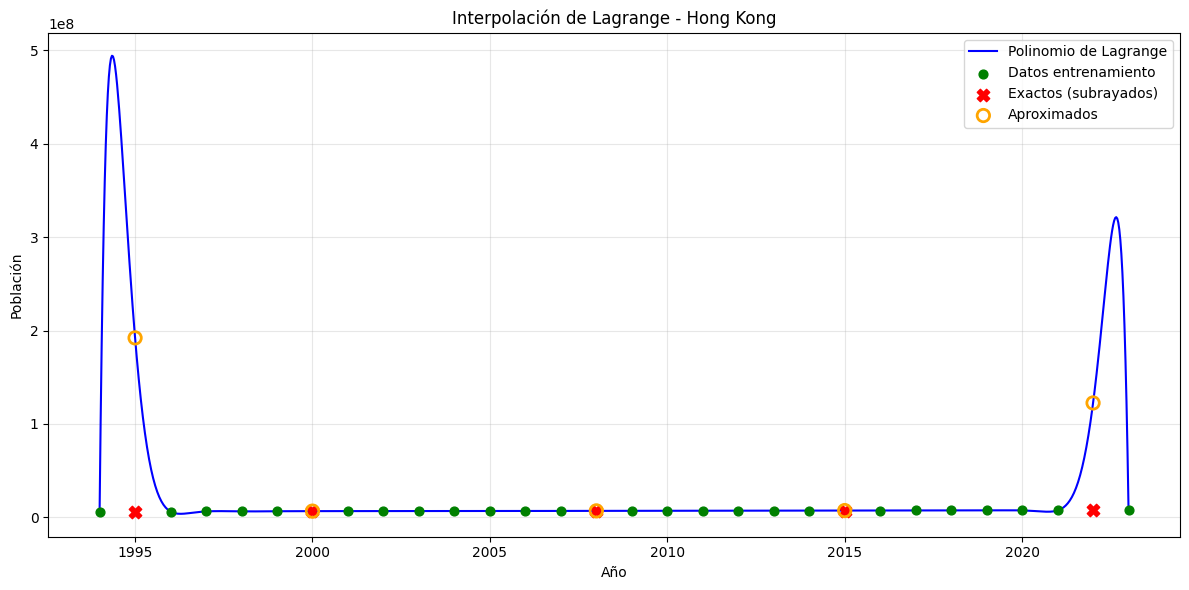

In [21]:
x_grafico = np.linspace(x_train.min(), x_train.max(), 1000)
y_grafico = lagrange(x_train, y_train, x_grafico)

plt.figure(figsize=(12, 6))
plt.plot(x_grafico, y_grafico, 'b-', label="Polinomio de Lagrange", linewidth=1.5)
plt.scatter(x_train, y_train, color='green', s=40, label="Datos entrenamiento", zorder=5)
plt.scatter(x_test, y_exacto, color='red', s=80, marker='X', label="Exactos (subrayados)", zorder=6)
plt.scatter(x_test, y_aprox, color='orange', s=80, marker='o', facecolors='none', linewidths=2, label="Aproximados", zorder=7)
plt.xlabel("Año")
plt.ylabel("Población")
plt.title("Interpolación de Lagrange - Hong Kong")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
